# CYBER SHIELD — Logistic Regression ilə şübhəli girişlərin aşkarlanması

**Məqsəd:** Giriş qeydlərinə əsasən girişin normal (`0`) və ya riskli (`1`) olduğunu proqnozlaşdıran Binary Classification modeli qurmaq.

Dataset süni yaradılıb və real istifadəçi/hücum qeydləri deyil. Tapşırıq PDF-dəki 6 missiya addımı bu notebook-da ardıcıllıqla yerinə yetirilir.

## 1. Məlumatı tanı
CSV faylını pandas ilə oxuyuruq və `head()`, `info()`, `describe()`, `isna().sum()` ilə araşdırırıq.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report
)

df = pd.read_csv("CyberShield_LogisticRegression_Dataset.csv")

print("İlk 5 sətir:")
display(df.head())

print("\\nMəlumat strukturu:")
df.info()

print("\\nTəsviri statistika:")
display(df.describe())

print("\\nBoş dəyərlərin sayı:")
display(df.isna().sum().to_frame("Missing values"))

print("\\nHədəf siniflərinin sayı:")
display(df["risky_login"].value_counts().sort_index().rename(index={0:"Normal (0)",1:"Riskli (1)"}).to_frame("Say"))

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-v7wlldya because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


İlk 5 sətir:


,login_id,login_hour,failed_attempts_24h,unknown_device,new_country,ip_risk_score,password_reset_7d,two_factor_enabled,account_age_days,last_login_gap_hours,vpn_used,risky_login
0,LOG-1101,15,1,1,0,40.6,0,1,100,20.0,0,0
1,LOG-0901,7,0,0,0,28.3,0,1,551,1.0,0,0
2,LOG-0758,0,0,1,1,43.8,0,1,423,19.0,0,1
3,LOG-0693,7,0,0,0,35.0,0,0,2522,8.0,0,1
4,LOG-0111,9,0,0,1,38.7,0,0,105,NaN,1,0


\nMəlumat strukturu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   login_id              1200 non-null   object 
 1   login_hour            1200 non-null   int64  
 2   failed_attempts_24h   1200 non-null   int64  
 3   unknown_device        1200 non-null   int64  
 4   new_country           1200 non-null   int64  
 5   ip_risk_score         1182 non-null   float64
 6   password_reset_7d     1200 non-null   int64  
 7   two_factor_enabled    1200 non-null   int64  
 8   account_age_days      1200 non-null   int64  
 9   last_login_gap_hours  1176 non-null   float64
 10  vpn_used              1200 non-null   int64  
 11  risky_login           1200 non-null   int64  
dtypes: float64(2), int64(9), object(1)
memory usage: 112.6+ KB
\nTəsviri statistika:


,login_hour,failed_attempts_24h,unknown_device,new_country,ip_risk_score,password_reset_7d,two_factor_enabled,account_age_days,last_login_gap_hours,vpn_used,risky_login
count,1200.000000,1200.000000,1200.000000,1200.000000,1182.000000,1200.000000,1200.000000,1200.000000,1176.000000,1200.00000,1200.000000
mean,11.645000,1.108333,0.180833,0.125833,38.184687,0.107500,0.663333,579.360833,23.651361,0.15000,0.301667
std,6.469326,1.047622,0.385040,0.331800,18.920628,0.309877,0.472767,647.128518,30.996651,0.35722,0.459173
min,0.000000,0.000000,0.000000,0.000000,1.600000,0.000000,0.000000,7.000000,1.000000,0.00000,0.000000
25%,7.000000,0.000000,0.000000,0.000000,23.500000,0.000000,0.000000,161.750000,6.000000,0.00000,0.000000
50%,11.000000,1.000000,0.000000,0.000000,36.700000,0.000000,1.000000,339.500000,14.000000,0.00000,0.000000
75%,17.000000,2.000000,0.000000,0.000000,50.600000,0.000000,1.000000,724.250000,28.000000,0.00000,1.000000
max,23.000000,6.000000,1.000000,1.000000,95.400000,1.000000,1.000000,3000.000000,320.000000,1.00000,1.000000


\nBoş dəyərlərin sayı:


,Missing values
login_id,0
login_hour,0
failed_attempts_24h,0
unknown_device,0
new_country,0
ip_risk_score,18
password_reset_7d,0
two_factor_enabled,0
account_age_days,0
last_login_gap_hours,24


\nHədəf siniflərinin sayı:


,Say
risky_login,
Normal (0),838
Riskli (1),362


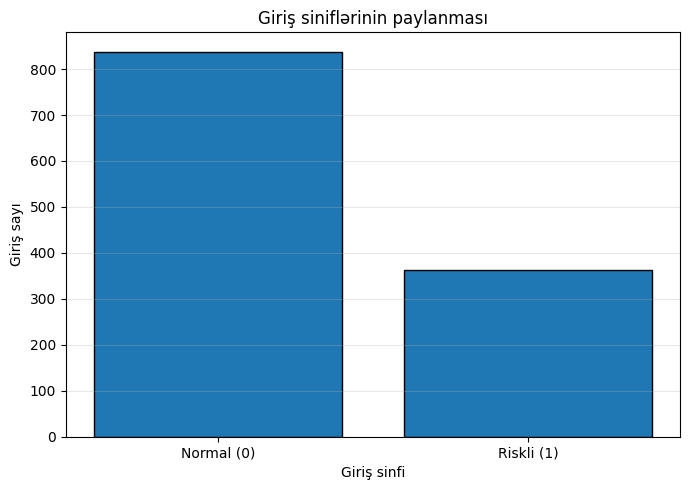

Normal girişlər: 838 (69.8%)
Riskli girişlər: 362 (30.2%)
Şərh: Siniflərin sayı və faizi datasetdə normal və riskli girişlərin balansını göstərir.


In [2]:
class_counts = df["risky_login"].value_counts().sort_index()
plt.figure(figsize=(7,5))
plt.bar(["Normal (0)", "Riskli (1)"], [class_counts.get(0,0), class_counts.get(1,0)], edgecolor="black")
plt.title("Giriş siniflərinin paylanması")
plt.xlabel("Giriş sinfi")
plt.ylabel("Giriş sayı")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

total = len(df)
print(f"Normal girişlər: {class_counts.get(0,0)} ({class_counts.get(0,0)/total:.1%})")
print(f"Riskli girişlər: {class_counts.get(1,0)} ({class_counts.get(1,0)/total:.1%})")
print("Şərh: Siniflərin sayı və faizi datasetdə normal və riskli girişlərin balansını göstərir.")

## 2. Hazırlıq gör

- `login_id` unikal identifikator olduğuna görə modeldən çıxarılır.
- `X` giriş xüsusiyyətlərindən, `y` isə yalnız `risky_login` hədəfindən ibarətdir.
- Məlumatlar 80% train və 20% test hissələrinə `stratify=y` ilə bölünür.
- Boş dəyərlər medianla doldurulur və `StandardScaler` tətbiq edilir.
- Imputer və scaler yalnız train məlumatında `fit` olunur. Pipeline bu ardıcıllığı qoruyur və məlumat sızmasının qarşısını alır.

In [3]:
X = df.drop(columns=["login_id", "risky_login"])
y = df["risky_login"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("X_train ölçüsü:", X_train.shape)
print("X_test ölçüsü:", X_test.shape)
print("Train hədəf payı:")
display(y_train.value_counts(normalize=True).sort_index().rename(index={0:"Normal (0)",1:"Riskli (1)"}).to_frame("Pay"))
print("Test hədəf payı:")
display(y_test.value_counts(normalize=True).sort_index().rename(index={0:"Normal (0)",1:"Riskli (1)"}).to_frame("Pay"))

model_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

X_train ölçüsü: (960, 10)
X_test ölçüsü: (240, 10)
Train hədəf payı:


,Pay
risky_login,
Normal (0),0.697917
Riskli (1),0.302083


Test hədəf payı:


,Pay
risky_login,
Normal (0),0.7
Riskli (1),0.3


## 3. Modeli öyrət
Logistic Regression modelini train hissəsində öyrədirik. Test üçün həm sinif proqnozu, həm də risk ehtimalı hesablanır.

In [4]:
model_pipeline.fit(X_train, y_train)

y_pred = model_pipeline.predict(X_test)
y_proba = model_pipeline.predict_proba(X_test)[:, 1]

print("İlk 10 proqnoz:")
display(pd.DataFrame({
    "Real sinif": y_test.iloc[:10].values,
    "Proqnoz sinfi": y_pred[:10],
    "Risk ehtimalı": y_proba[:10].round(3)
}, index=y_test.index[:10]))

İlk 10 proqnoz:


,Real sinif,Proqnoz sinfi,Risk ehtimalı
576,0,0,0.267
691,1,0,0.301
292,0,0,0.124
558,0,0,0.107
596,0,0,0.194
525,0,0,0.260
914,0,0,0.126
853,1,0,0.415
187,0,0,0.493
705,0,0,0.067


## 4. Səhvləri araşdır
Confusion Matrix və Accuracy, Precision, Recall, F1-score metriklərini hesablayırıq. Standart ehtimal həddi 0.50-dir.

Confusion Matrix:
[[149  19]
 [ 45  27]]


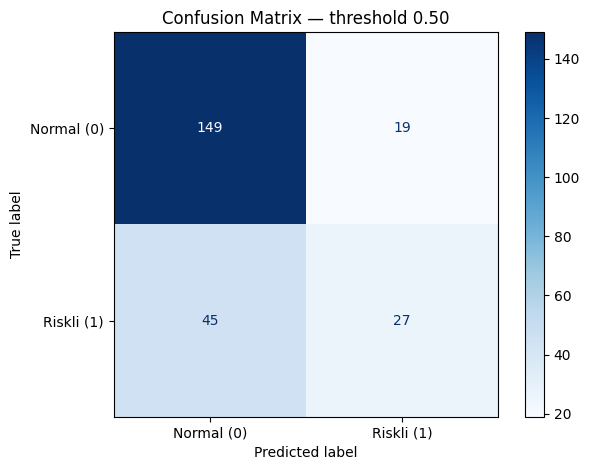

,Metrik,Nəticə
0,Accuracy,0.7333
1,Precision,0.5870
2,Recall,0.3750
3,F1-score,0.4576


              precision    recall  f1-score   support

  Normal (0)       0.77      0.89      0.82       168
  Riskli (1)       0.59      0.38      0.46        72

    accuracy                           0.73       240
   macro avg       0.68      0.63      0.64       240
weighted avg       0.71      0.73      0.71       240



In [5]:
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal (0)", "Riskli (1)"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — threshold 0.50")
plt.tight_layout()
plt.show()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

metrics_table = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Nəticə": [accuracy, precision, recall, f1]
})
display(metrics_table.round(4))
print(classification_report(y_test, y_pred, target_names=["Normal (0)", "Riskli (1)"], zero_division=0))

### FP və FN nə deməkdir?

- **FP (False Positive):** Əslində normal olan giriş riskli kimi işarələnir. Bu, istifadəçiyə əlavə yoxlama və ya müvəqqəti narahatlıq yarada bilər.
- **FN (False Negative):** Əslində riskli olan giriş normal kimi qəbul edilir. Bu, şübhəli girişin aşkarlanmadan keçməsi deməkdir.

**Təhlükəsizlik baxımından FN adətən daha risklidir**, çünki potensial hücum və ya icazəsiz giriş sistem tərəfindən buraxıla bilər. Bununla belə, çox aşağı ehtimal həddi FP sayını artıra və çoxlu normal girişlərin əlavə yoxlanmasına səbəb ola bilər.

## 5. Nəticəni göstər
Ən azı iki qrafik: siniflərin paylanması və Confusion Matrix artıq qurulub. Əlavə olaraq model əmsallarını vizuallaşdırırıq.

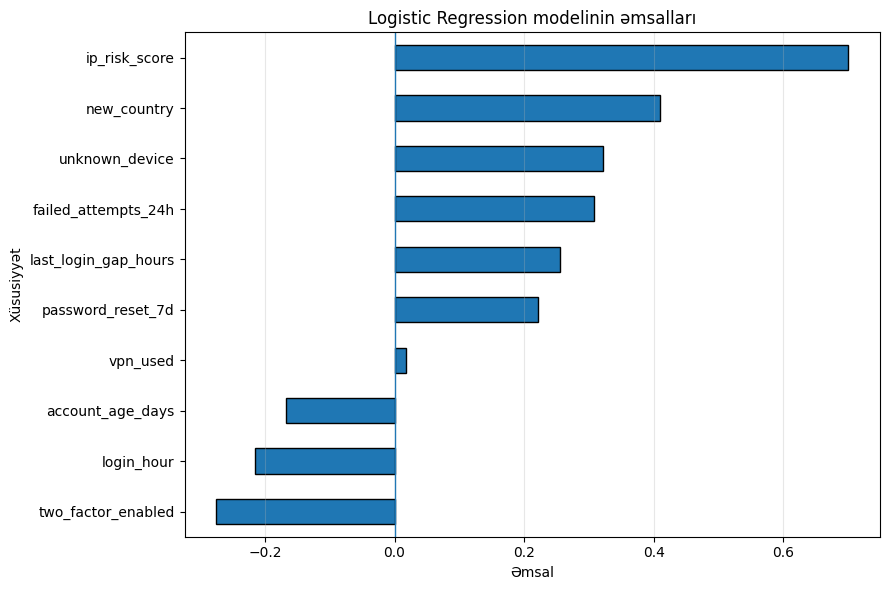

,Əmsal
ip_risk_score,0.7005
new_country,0.4096
unknown_device,0.3218
failed_attempts_24h,0.3085
last_login_gap_hours,0.2551
password_reset_7d,0.2218
vpn_used,0.0183
account_age_days,-0.1678
login_hour,-0.2150
two_factor_enabled,-0.2753


Şərh: Müsbət əmsal, digər xüsusiyyətlər sabit olduqda, riskli sinifin log-odds dəyərini artırır; mənfi əmsal azaldır. Əmsalın ölçüsü xüsusiyyətin miqyası və digər xüsusiyyətlərlə əlaqəsi nəzərə alınaraq şərh edilməlidir.


In [6]:
fitted_model = model_pipeline.named_steps["model"]
coefficients = pd.Series(fitted_model.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(9,6))
coefficients.plot(kind="barh", edgecolor="black")
plt.title("Logistic Regression modelinin əmsalları")
plt.xlabel("Əmsal")
plt.ylabel("Xüsusiyyət")
plt.axvline(0, linewidth=1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

display(coefficients.sort_values(ascending=False).rename("Əmsal").to_frame().round(4))
print("Şərh: Müsbət əmsal, digər xüsusiyyətlər sabit olduqda, riskli sinifin log-odds dəyərini artırır; mənfi əmsal azaldır. Əmsalın ölçüsü xüsusiyyətin miqyası və digər xüsusiyyətlərlə əlaqəsi nəzərə alınaraq şərh edilməlidir.")

## 6. Qərar ver — 0.30 və 0.50 ehtimal hədlərinin müqayisəsi
Hədd 0.30 olduqda riskli kimi işarələmək daha asanlaşır. Bu, riskli girişlərin daha çoxunu tutmağa (Recall artımına) kömək edə bilər, amma FP də arta bilər.

In [7]:
threshold_rows = []
threshold_predictions = {}

for threshold in [0.30, 0.50]:
    pred_threshold = (y_proba >= threshold).astype(int)
    threshold_predictions[threshold] = pred_threshold
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred_threshold, labels=[0,1]).ravel()
    threshold_rows.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, pred_threshold),
        "Precision": precision_score(y_test, pred_threshold, zero_division=0),
        "Recall": recall_score(y_test, pred_threshold, zero_division=0),
        "F1-score": f1_score(y_test, pred_threshold, zero_division=0),
        "TN": tn_t, "FP": fp_t, "FN": fn_t, "TP": tp_t
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(4))

,Threshold,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,0.3,0.7542,0.5714,0.7222,0.6380,129,39,20,52
1,0.5,0.7333,0.5870,0.3750,0.4576,149,19,45,27


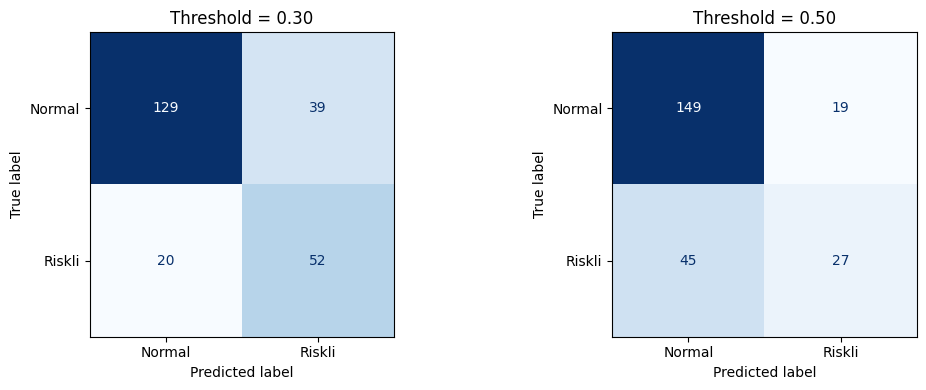

Threshold 0.30: Recall=0.722, FP=39, FN=20
Threshold 0.50: Recall=0.375, FP=19, FN=45
Nəticə: 0.30 həddi test dəstində daha yüksək Recall verir və riskli girişlərin daha böyük hissəsini tutur.
Təhlükəsizlik qərarı: FN xərci yüksəkdirsə, 0.30 kimi aşağı hədd seçilə bilər. Lakin əlavə yoxlamaların sayı (FP) da nəzərə alınmalıdır.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax, threshold in zip(axes, [0.30, 0.50]):
    cm_t = confusion_matrix(y_test, threshold_predictions[threshold], labels=[0,1])
    ConfusionMatrixDisplay(cm_t, display_labels=["Normal", "Riskli"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"Threshold = {threshold:.2f}")
plt.tight_layout()
plt.show()

row30 = threshold_table.loc[threshold_table["Threshold"] == 0.30].iloc[0]
row50 = threshold_table.loc[threshold_table["Threshold"] == 0.50].iloc[0]
print(f"Threshold 0.30: Recall={row30['Recall']:.3f}, FP={int(row30['FP'])}, FN={int(row30['FN'])}")
print(f"Threshold 0.50: Recall={row50['Recall']:.3f}, FP={int(row50['FP'])}, FN={int(row50['FN'])}")

if row30["Recall"] > row50["Recall"]:
    print("Nəticə: 0.30 həddi test dəstində daha yüksək Recall verir və riskli girişlərin daha böyük hissəsini tutur.")
elif row30["Recall"] < row50["Recall"]:
    print("Nəticə: 0.50 həddi test dəstində daha yüksək Recall verir.")
else:
    print("Nəticə: Hər iki hədd test dəstində eyni Recall verir.")

print("Təhlükəsizlik qərarı: FN xərci yüksəkdirsə, 0.30 kimi aşağı hədd seçilə bilər. Lakin əlavə yoxlamaların sayı (FP) da nəzərə alınmalıdır.")

### 3 yeni giriş üçün proqnoz
Aşağıdakı üç nümunə tapşırıq üçün yaradılmış sınaq girişləridir. Model hər biri üçün risk ehtimalını və 0.30/0.50 hədlərinə görə qərarı göstərir.

In [9]:
new_logins = pd.DataFrame([
    {
        "login_hour": 2, "failed_attempts_24h": 6, "unknown_device": 1,
        "new_country": 1, "ip_risk_score": 88, "password_reset_7d": 1,
        "two_factor_enabled": 0, "account_age_days": 18,
        "last_login_gap_hours": 140, "vpn_used": 1
    },
    {
        "login_hour": 14, "failed_attempts_24h": 0, "unknown_device": 0,
        "new_country": 0, "ip_risk_score": 12, "password_reset_7d": 0,
        "two_factor_enabled": 1, "account_age_days": 900,
        "last_login_gap_hours": 8, "vpn_used": 0
    },
    {
        "login_hour": 23, "failed_attempts_24h": 3, "unknown_device": 1,
        "new_country": 0, "ip_risk_score": 65, "password_reset_7d": 0,
        "two_factor_enabled": 1, "account_age_days": 120,
        "last_login_gap_hours": 72, "vpn_used": 1
    }
])

new_probabilities = model_pipeline.predict_proba(new_logins)[:, 1]
new_results = new_logins.copy()
new_results["Risk ehtimalı"] = new_probabilities.round(3)
new_results["Qərar (0.30)"] = np.where(new_probabilities >= 0.30, "RİSKLİ (1)", "NORMAL (0)")
new_results["Qərar (0.50)"] = np.where(new_probabilities >= 0.50, "RİSKLİ (1)", "NORMAL (0)")
display(new_results)

,login_hour,failed_attempts_24h,unknown_device,new_country,ip_risk_score,password_reset_7d,two_factor_enabled,account_age_days,last_login_gap_hours,vpn_used,Risk ehtimalı,Qərar (0.30),Qərar (0.50)
0,2,6,1,1,88,1,0,18,140,1,0.999,RİSKLİ (1),RİSKLİ (1)
1,14,0,0,0,12,0,1,900,8,0,0.039,NORMAL (0),NORMAL (0)
2,23,3,1,0,65,0,1,120,72,1,0.732,RİSKLİ (1),RİSKLİ (1)


## Yekun izah

Bu layihədə giriş qeydlərinin `risky_login` hədəfinə görə normal (0) və riskli (1) kimi təsnifatı üçün Logistic Regression modeli quruldu. `login_id` identifikator olduğuna görə modeldən çıxarıldı. Boş dəyərlər medianla dolduruldu və xüsusiyyətlər standartlaşdırıldı; hər iki emal addımı yalnız train hissəsində öyrədildi. Məlumatlar `stratify` ilə 80/20 bölündü.

Model Accuracy, Precision, Recall və F1-score ilə qiymətləndirildi. Confusion Matrix FP və FN səhvlərini göstərdi. Kibertəhlükəsizlikdə FN — riskli girişin normal kimi buraxılması — adətən daha ciddi nəticə yarada bilər. 0.30 və 0.50 hədləri Recall, FP və FN baxımından müqayisə edildi. Son qərar təhlükəsizlik prioriteti ilə yanaşı yanlış xəbərdarlıqların əməliyyat xərci nəzərə alınaraq verilməlidir.

**Məhdudiyyət:** Dataset süni yaradılıb; nəticələr real sistemdə təhlükəsizlik zəmanəti kimi qəbul edilməməlidir.